# Experiment 6: LoRA during continued pretraining

Does restricting credit-domain CPT to low-rank attention updates change its training dynamics? The separate campaign has 48 planned runs: TabPFN v3 and TabICLv2, three learning rates, four held-out dataset partitions and PD/LGD. Rank 16 and alpha 32 stay fixed; only attention query/value LoRA factors are optimized. The target table remains excluded from CPT.

## 0. Evidence and scope

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, lora_study as ls, publication as pub
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('experiment6/01_training')
report = cp.NotebookReport('Experiment 6: LoRA during continued pretraining', sink=sink)
print(source_description())
report.add('0. Evidence and scope', source_description() + '\n' + 'Training trajectories describe cross-table adaptation. Pending local evidence is not a live scheduler status; final prediction quality belongs in the results notebook.')
runs = [cp.load_campaign(8, track) for track in ('pd', 'lgd')]
from src.visualize import pilots as pv


DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


## 1. LoRA recipe and training coverage

In [2]:
for run in runs:
    report.table(run.track.upper()+' protocol', ls.protocol_table(run))
    report.table(run.track.upper()+' evidence', pub.availability(run))
    report.table(run.track.upper()+' planned and recorded trials', ls.coverage_table(run))
report.add('1. LoRA recipe and training coverage', 'No measurements are synthesized for pending runs. This rank/alpha recipe is one constrained adaptation design; it does not establish an optimal LoRA configuration. Completed training does not imply completed benchmarking.')

,Setting,Value
0,Run identity,cpt_lora_v1
1,Task,PD
2,Adaptation,Low-rank updates to all attention query/value ...
3,Rank,16
4,Alpha,32
5,Adapter dropout,0.0
6,Factor weight decay,0.0
7,Training precision,AMP (BF16 on B200); LoRA factors and BA produc...
8,Learning rates,"1e-05, 0.0001, 0.001"
9,L2-SP,0


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,18888,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1815,Project final evaluation


,base,learning_rate,planned,completed,recorded_outcomes,evidence
0,TabICLv2,0.00001,4,4,OK: 4,Recorded local outcomes
1,TabICLv2,0.00010,4,4,OK: 4,Recorded local outcomes
2,TabICLv2,0.00100,4,4,OK: 4,Recorded local outcomes
3,TabPFN v3,0.00001,4,4,OK: 4,Recorded local outcomes
4,TabPFN v3,0.00010,4,4,OK: 4,Recorded local outcomes
5,TabPFN v3,0.00100,4,4,OK: 4,Recorded local outcomes


,Setting,Value
0,Run identity,cpt_lora_v1
1,Task,LGD
2,Adaptation,Low-rank updates to all attention query/value ...
3,Rank,16
4,Alpha,32
5,Adapter dropout,0.0
6,Factor weight decay,0.0
7,Training precision,AMP (BF16 on B200); LoRA factors and BA produc...
8,Learning rates,"1e-05, 0.0001, 0.001"
9,L2-SP,0


,evidence,records,origin
0,Planned trials,24,Config; not scheduler state
1,Completed trials,24,DATA manifests
2,Epoch rows,40032,Project training diagnostics
3,Milestone rows,144,Project trajectory diagnostics
4,Benchmark folds,1320,Project final evaluation


,base,learning_rate,planned,completed,recorded_outcomes,evidence
0,TabICLv2,0.00001,4,4,OK: 4,Recorded local outcomes
1,TabICLv2,0.00010,4,4,OK: 4,Recorded local outcomes
2,TabICLv2,0.00100,4,4,OK: 4,Recorded local outcomes
3,TabPFN v3,0.00001,4,4,OK: 4,Recorded local outcomes
4,TabPFN v3,0.00010,4,4,OK: 4,Recorded local outcomes
5,TabPFN v3,0.00100,4,4,OK: 4,Recorded local outcomes


## 2. Loss, gradients and effective weight movement

One compact dashboard per model and task separates native query loss, optimizer gradients, effective attention-weight displacement and recorded training time. Curves require all four planned dataset partitions at each learning rate.

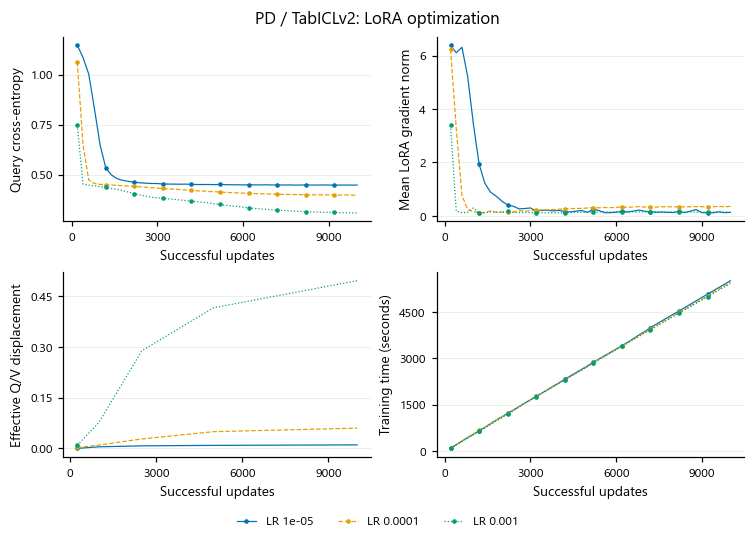

Training seed: 42. LoRA diagnostics averaged over every planned dataset partition at each learning rate. Missing partitions leave gaps. Data loss is the architecture's native query objective; epochs without complete training-table coverage are omitted. Gradient norms concern optimizer-selected LoRA factors. Effective displacement is the Frobenius norm of the induced query/value weight update divided by the initial targeted query/value weight norm, not relative displacement of zero-initialized adapter factors. Time is recorded training wall time and excludes queue wait. Losses are never pooled across architectures.

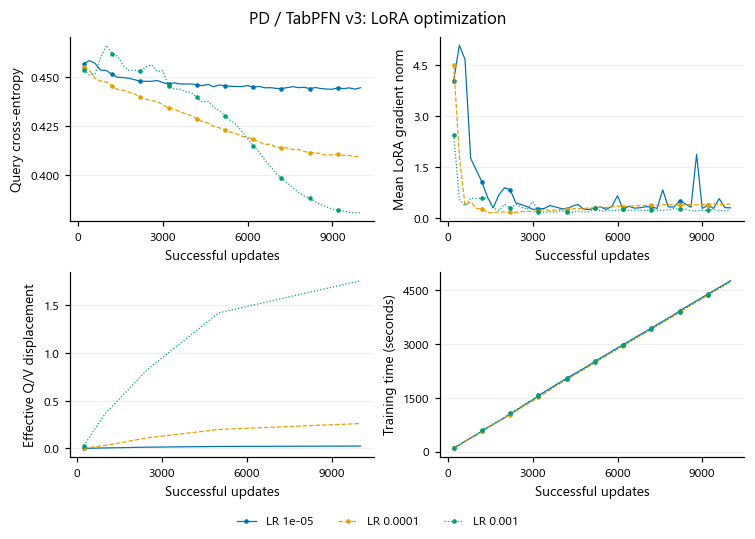

Training seed: 42. LoRA diagnostics averaged over every planned dataset partition at each learning rate. Missing partitions leave gaps. Data loss is the architecture's native query objective; epochs without complete training-table coverage are omitted. Gradient norms concern optimizer-selected LoRA factors. Effective displacement is the Frobenius norm of the induced query/value weight update divided by the initial targeted query/value weight norm, not relative displacement of zero-initialized adapter factors. Time is recorded training wall time and excludes queue wait. Losses are never pooled across architectures.

,base,learning_rate,l2sp_lambda,frozen,sampling,partition,seed,epochs,nonfinite_diagnostics,peak_epoch_gradient,peak_epoch_clipped_fraction,peak_l2sp_penalty,amp_skips,data_skips,peak_weight_drift
0,TabPFN v3,0.00001,0.0,False,one_sample,0,42,770,0,56.589275,0.230769,0.0,0,0,0.024076
1,TabPFN v3,0.00010,0.0,False,one_sample,0,42,770,0,28.445977,0.230769,0.0,0,0,0.281339
2,TabPFN v3,0.00100,0.0,False,one_sample,0,42,770,0,12.488906,0.230769,0.0,0,0,1.831706
3,TabICLv2,0.00001,0.0,False,one_sample,0,42,770,0,11.123968,0.923077,0.0,0,0,0.010088
4,TabICLv2,0.00010,0.0,False,one_sample,0,42,770,0,9.169042,0.846154,0.0,0,0,0.058023
5,TabICLv2,0.00100,0.0,False,one_sample,0,42,770,0,7.229942,0.846154,0.0,0,0,0.505089
6,TabPFN v3,0.00001,0.0,False,one_sample,1,42,770,0,42.411957,0.230769,0.0,0,0,0.025509
7,TabPFN v3,0.00010,0.0,False,one_sample,1,42,770,0,11.853340,0.333333,0.0,0,0,0.195434
8,TabPFN v3,0.00100,0.0,False,one_sample,1,42,770,0,13.703909,0.307692,0.0,0,0,1.878117
9,TabICLv2,0.00001,0.0,False,one_sample,1,42,770,0,10.801880,0.769231,0.0,0,0,0.010145


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,recorded_epochs,full_coverage_epochs,fullest_observed_tables,min_observed_tables,last_update,partial_coverage_epochs
0,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00100,0.0,False,one_sample,770,769,13,3,10000,1
1,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00010,0.0,False,one_sample,770,769,13,3,10000,1
2,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00001,0.0,False,one_sample,770,769,13,3,10000,1
3,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00100,0.0,False,one_sample,770,769,13,3,10000,1
4,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00010,0.0,False,one_sample,770,769,13,3,10000,1
5,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00001,0.0,False,one_sample,770,769,13,3,10000,1
6,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00100,0.0,False,one_sample,770,769,13,3,10000,1
7,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00010,0.0,False,one_sample,770,769,13,3,10000,1
8,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00001,0.0,False,one_sample,770,769,13,3,10000,1
9,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00100,0.0,False,one_sample,770,769,13,3,10000,1


,trial_name,successful_updates,train_loss,observed_tables,full_observed_tables,complete_pass,base,learning_rate,l2sp_lambda,frozen,sampling
0,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,10000,0.490846,3,13,False,TabICLv2,0.00100,0.0,False,one_sample
1,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,10000,0.502443,3,13,False,TabICLv2,0.00010,0.0,False,one_sample
2,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,10000,0.511817,3,13,False,TabICLv2,0.00001,0.0,False,one_sample
3,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,10000,0.503045,3,13,False,TabPFN v3,0.00100,0.0,False,one_sample
4,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,10000,0.502496,3,13,False,TabPFN v3,0.00010,0.0,False,one_sample
5,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,10000,0.511945,3,13,False,TabPFN v3,0.00001,0.0,False,one_sample
6,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,10000,0.110172,3,13,False,TabICLv2,0.00100,0.0,False,one_sample
7,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,10000,0.237879,3,13,False,TabICLv2,0.00010,0.0,False,one_sample
8,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,10000,0.343187,3,13,False,TabICLv2,0.00001,0.0,False,one_sample
9,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,10000,0.155928,3,13,False,TabPFN v3,0.00100,0.0,False,one_sample


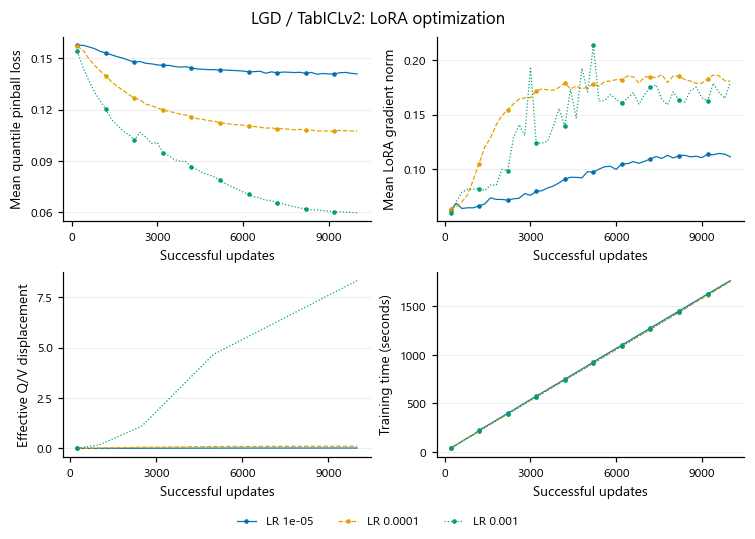

Training seed: 42. LoRA diagnostics averaged over every planned dataset partition at each learning rate. Missing partitions leave gaps. Data loss is the architecture's native query objective; epochs without complete training-table coverage are omitted. Gradient norms concern optimizer-selected LoRA factors. Effective displacement is the Frobenius norm of the induced query/value weight update divided by the initial targeted query/value weight norm, not relative displacement of zero-initialized adapter factors. Time is recorded training wall time and excludes queue wait. Losses are never pooled across architectures.

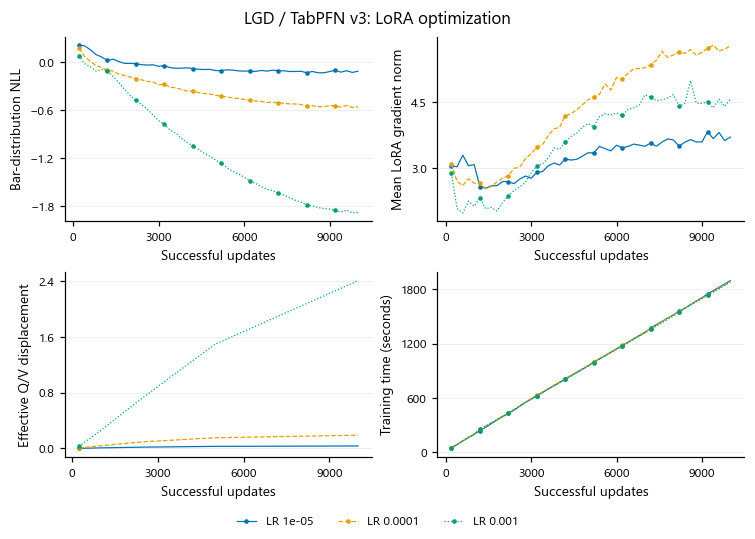

Training seed: 42. LoRA diagnostics averaged over every planned dataset partition at each learning rate. Missing partitions leave gaps. Data loss is the architecture's native query objective; epochs without complete training-table coverage are omitted. Gradient norms concern optimizer-selected LoRA factors. Effective displacement is the Frobenius norm of the induced query/value weight update divided by the initial targeted query/value weight norm, not relative displacement of zero-initialized adapter factors. Time is recorded training wall time and excludes queue wait. Losses are never pooled across architectures.

,base,learning_rate,l2sp_lambda,frozen,sampling,partition,seed,epochs,nonfinite_diagnostics,peak_epoch_gradient,peak_epoch_clipped_fraction,peak_l2sp_penalty,amp_skips,data_skips,peak_weight_drift
0,TabPFN v3,0.00001,0.0,False,one_sample,0,42,1667,0,9.094850,1.000000,0.0,0,0,0.034434
1,TabPFN v3,0.00010,0.0,False,one_sample,0,42,1667,0,13.716248,1.000000,0.0,0,0,0.176341
2,TabPFN v3,0.00100,0.0,False,one_sample,0,42,1667,0,8.034482,1.000000,0.0,0,0,1.421922
3,TabICLv2,0.00001,0.0,False,one_sample,0,42,1667,0,0.186466,0.000000,0.0,0,0,0.020050
4,TabICLv2,0.00010,0.0,False,one_sample,0,42,1667,0,0.345539,0.166667,0.0,0,0,0.109985
5,TabICLv2,0.00100,0.0,False,one_sample,0,42,1667,0,4.242287,0.666667,0.0,0,0,8.639638
6,TabPFN v3,0.00001,0.0,False,one_sample,1,42,1667,0,4.917618,1.000000,0.0,0,0,0.035532
7,TabPFN v3,0.00010,0.0,False,one_sample,1,42,1667,0,29.274267,1.000000,0.0,0,0,0.194100
8,TabPFN v3,0.00100,0.0,False,one_sample,1,42,1667,0,30.957223,1.000000,0.0,0,0,1.506811
9,TabICLv2,0.00001,0.0,False,one_sample,1,42,1667,0,0.205101,0.000000,0.0,0,0,0.016830


,trial_name,base,learning_rate,l2sp_lambda,frozen,sampling,recorded_epochs,full_coverage_epochs,fullest_observed_tables,min_observed_tables,last_update,partial_coverage_epochs
0,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00100,0.0,False,one_sample,1667,1666,6,4,10000,1
1,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00010,0.0,False,one_sample,1667,1666,6,4,10000,1
2,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00001,0.0,False,one_sample,1667,1666,6,4,10000,1
3,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00100,0.0,False,one_sample,1667,1666,6,4,10000,1
4,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00010,0.0,False,one_sample,1667,1666,6,4,10000,1
5,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00001,0.0,False,one_sample,1667,1666,6,4,10000,1
6,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00100,0.0,False,one_sample,1667,1666,6,4,10000,1
7,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00010,0.0,False,one_sample,1667,1666,6,4,10000,1
8,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00001,0.0,False,one_sample,1667,1666,6,4,10000,1
9,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00100,0.0,False,one_sample,1667,1666,6,4,10000,1


,trial_name,successful_updates,train_loss,observed_tables,full_observed_tables,complete_pass,base,learning_rate,l2sp_lambda,frozen,sampling
0,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,10000,0.040542,4,6,False,TabICLv2,0.00100,0.0,False,one_sample
1,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,10000,0.082850,4,6,False,TabICLv2,0.00010,0.0,False,one_sample
2,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,10000,0.118883,4,6,False,TabICLv2,0.00001,0.0,False,one_sample
3,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,10000,-2.387005,4,6,False,TabPFN v3,0.00100,0.0,False,one_sample
4,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,10000,-1.032144,4,6,False,TabPFN v3,0.00010,0.0,False,one_sample
5,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,10000,-0.466344,4,6,False,TabPFN v3,0.00001,0.0,False,one_sample
6,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,10000,0.061680,4,6,False,TabICLv2,0.00100,0.0,False,one_sample
7,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,10000,0.112689,4,6,False,TabICLv2,0.00010,0.0,False,one_sample
8,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,10000,0.131796,4,6,False,TabICLv2,0.00001,0.0,False,one_sample
9,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,10000,-1.611331,4,6,False,TabPFN v3,0.00100,0.0,False,one_sample


In [3]:
for run in runs:
    cp.show(sink, ls.plot_optimization(run))
    report.table(run.track.upper()+' numerical health', pv.health_table(run))
    for label, table in cp.loss_coverage_tables(run).items():
        report.table(run.track.upper()+' '+label, table)
report.add('2. Loss, gradients and effective weight movement', 'PD data loss is query cross-entropy. LGD retains the native objective of each architecture: TabPFN bar-distribution NLL or TabICL mean quantile pinball loss. No L2-SP term is applied. Effective Q/V displacement measures the induced weight update against initial targeted weights; it is not relative change from zero-valued adapter factors. Skipped and clipped updates remain in the health table, including exact zeros.')

## 3. Credit transfer and non-credit retention

Fixed-context AUC and R² monitors show changes during training. They are distinct from the five-fold evaluation of excluded tables.

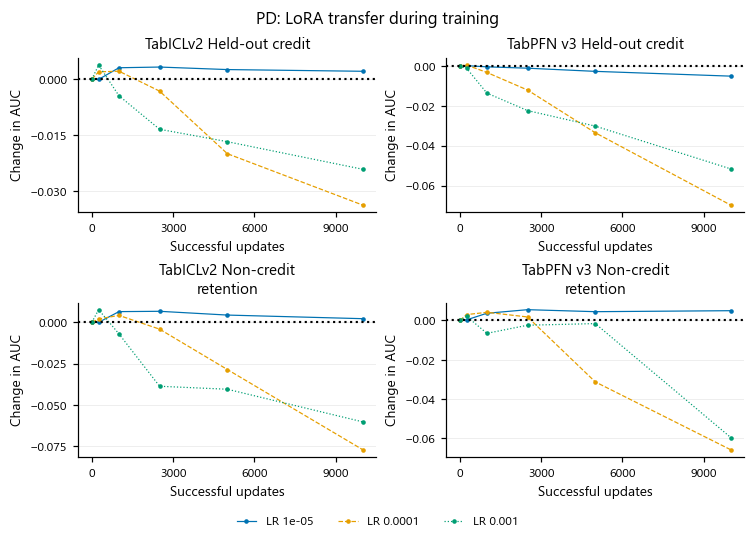

Training seed: 42. Change in AUC from each table's update-zero score during LoRA CPT. Repeated non-credit observations are averaged within table; tables receive equal weight. Every planned partition and the unchanged baseline cohort are required at each milestone. Rates can have different monitor cohorts if baseline measurements are absent; the support table identifies these omissions. These fixed-context training monitors are distinct from the final five-fold benchmark.

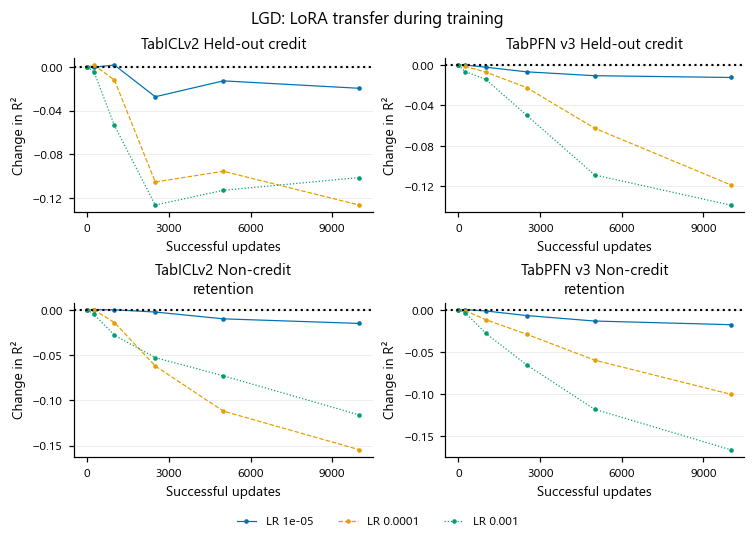

Training seed: 42. Change in R² from each table's update-zero score during LoRA CPT. Repeated non-credit observations are averaged within table; tables receive equal weight. Every planned partition and the unchanged baseline cohort are required at each milestone. Rates can have different monitor cohorts if baseline measurements are absent; the support table identifies these omissions. These fixed-context training monitors are distinct from the final five-fold benchmark.

In [4]:
for run in runs:
    cp.show(sink, ls.plot_monitors(run))
report.add('3. Credit transfer and non-credit retention', 'Each monitor observation is paired with the same table and trial at update zero. Tables receive equal weight; repeated non-credit partitions are averaged within table. Missing planned support leaves a gap rather than a zero effect.')

## 4. Learning-rate schedule and computational cost

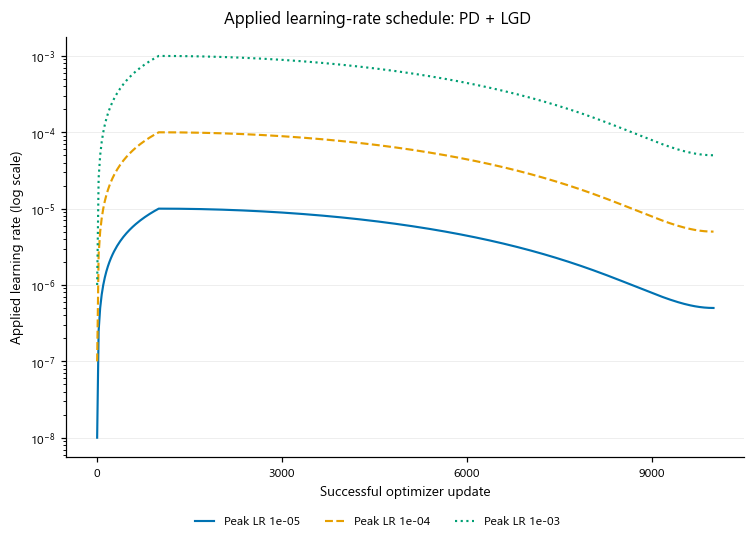

Learning rates evaluated from the recorded campaign configuration using the training scheduler. Each distinct peak-rate schedule is drawn once, pooling tasks only when budget, warmup and decay floor agree. The rate for update u is the scheduler value before that update (index u minus one). The first update has zero learning rate and is omitted from the logarithmic axis, but retained in the table. These are configured schedules; measured epoch-end rates and their sampling intervals are reported separately.

,trial_name,base,learning_rate,partition,seed,status,optimizer_selected_lora_parameters,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,relative_effective_qv_displacement
0,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00001,0,42,OK,860160,54013304,195157151,5178.202935,1.438390,83.683,0.024076
1,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00010,0,42,OK,860160,54013304,195157151,5174.528606,1.437369,83.683,0.281339
2,cpt_lora_v1_s00_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00100,0,42,OK,860160,54013304,195157151,5177.802615,1.438279,83.683,1.831706
3,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00001,0,42,OK,466944,28019202,195157151,6043.083728,1.678634,25.476,0.010088
4,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00010,0,42,OK,466944,28019202,195157151,5940.545044,1.650151,25.476,0.058023
5,cpt_lora_v1_s00_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00100,0,42,OK,466944,28019202,195157151,5926.280326,1.646189,25.476,0.505089
6,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00001,1,42,OK,860160,54013304,179895410,5039.597074,1.399888,83.683,0.025509
7,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00010,1,42,OK,860160,54013304,179895410,4982.094286,1.383915,83.683,0.195434
8,cpt_lora_v1_s01_pd_tabpfn-v3-classifier-v3_def...,TabPFN v3,0.00100,1,42,OK,860160,54013304,179895410,4969.911524,1.380531,83.683,1.878117
9,cpt_lora_v1_s01_pd_tabicl-classifier-v2-202602...,TabICLv2,0.00001,1,42,OK,466944,28019202,179895410,5646.398277,1.568444,25.476,0.010145


,trial_name,base,learning_rate,partition,seed,status,optimizer_selected_lora_parameters,total_params,rows_seen,elapsed_sec,gpu_hours,peak_gpu_gb,relative_effective_qv_displacement
0,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00001,0,42,OK,860160,59135104,82784961,2135.081013,0.593078,32.567,0.034434
1,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00010,0,42,OK,860160,59135104,82784961,2038.587626,0.566274,32.567,0.176341
2,cpt_lora_v1_s00_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00100,0,42,OK,860160,59135104,82784961,2014.511486,0.559587,32.567,1.421922
3,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00001,0,42,OK,466944,29011935,82784961,1990.954082,0.553043,10.545,0.020050
4,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00010,0,42,OK,466944,29011935,82784961,2012.639926,0.559067,10.545,0.109985
5,cpt_lora_v1_s00_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00100,0,42,OK,466944,29011935,82784961,2058.362082,0.571767,10.545,8.639638
6,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00001,1,42,OK,860160,59135104,24755261,1245.984178,0.346107,14.673,0.035532
7,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00010,1,42,OK,860160,59135104,24755261,1327.134023,0.368648,14.673,0.194100
8,cpt_lora_v1_s01_lgd_tabpfn-v3-regressor-v3_def...,TabPFN v3,0.00100,1,42,OK,860160,59135104,24755261,1321.105155,0.366974,14.673,1.506811
9,cpt_lora_v1_s01_lgd_tabicl-regressor-v2-202602...,TabICLv2,0.00001,1,42,OK,466944,29011935,24755261,898.383233,0.249551,4.144,0.016830


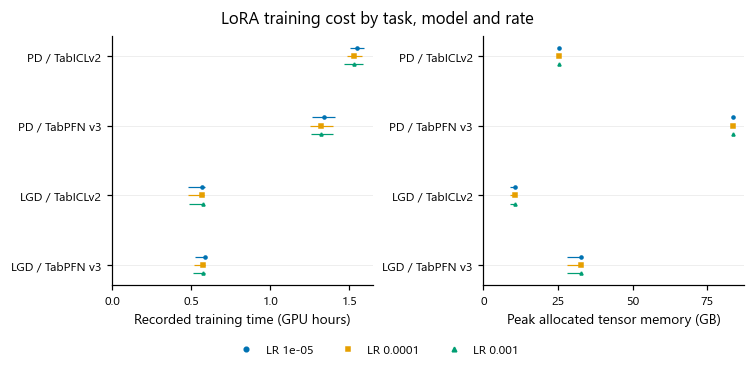

LoRA training cost with only low-rank query/value factors optimized. PD: Training seed: 42. LGD: Training seed: 42. Points and horizontal intervals show medians and interquartile ranges over completed dataset partitions within each task, model and learning rate, not confidence intervals. Each completed trial contributes once; counts accompany the figure. Missing or unfinished costs are not zeros. Time excludes queue wait, and memory is peak allocated tensor memory rather than total device capacity.

In [5]:
cp.show(sink, ls.plot_schedule(runs))
for run in runs:
    report.table(run.track.upper()+' adapter parameters and training resources', ls.costs(run))
cp.show(sink, ls.plot_costs(runs))
report.add('4. Learning-rate schedule and computational cost', 'A shared configured schedule is shown once after training evidence exists; observed rates remain in its source table. The joint cost figure keeps task, model and rate separate. Completed-trial time excludes queue wait, and memory is peak allocated tensor memory. Missing costs remain unavailable; this is not an equal-compute comparison with full-parameter CPT.')

## Additional TabPFN v2 and v2.6 coverage

The exploratory extension preserves the original dataset partitions and reports its evidence separately.

In [6]:
from src.visualize import legacy_extensions
legacy_extensions.render(report, sink, 8, 'training')

## Complete text summary

All displayed values, tables and captions in section order.

In [7]:
print(report.summary(sink))

Experiment 6: LoRA during continued pretraining

0. Evidence and scope
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
Training trajectories describe cross-table adaptation. Pending local evidence is not a live scheduler status; final prediction quality belongs in the results notebook.

1. LoRA recipe and training coverage
No measurements are synthesized for pending runs. This rank/alpha recipe is one constrained adaptation design; it does not establish an optimal LoRA configuration. Completed training does not imply completed benchmarking.

Table: PD protocol
CSV (first column: row index)
row,Setting,Value
0,Run identity,cpt_lora_v1
1,Task,PD
2,Adaptation,Low-rank updates to all attention query/value projections; base weights fixed
3,Rank,16
4,Alpha,32
5,Adapter dropout,0.0
6,Factor weight decay,0.0
7,Training precision,AMP (BF16 on B200); LoRA factors and BA product FP32
8,